# Étape 4 — Baseline BM25 et évaluation du retrieval

Ce notebook construit le premier véritable retriever du projet. Il crée un index BM25 distinct pour chacune des quatre stratégies de chunking, évalue les requêtes `train` et `validation`, règle `k1` et `b` sur la validation, mesure la couverture des spans et la latence, puis produit des artefacts versionnés.

Le split `test` reste **verrouillé et non chargé**. Les paramètres et les stratégies ne doivent jamais être choisis à partir du test.

## 1. Dépendances

In [1]:
%pip install -q numpy pandas matplotlib scipy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
from __future__ import annotations

import hashlib
import json
import platform
import re
import time
import unicodedata
from collections import Counter
from datetime import datetime, timezone
from pathlib import Path
from typing import Any, Iterable

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
from IPython.display import display
from scipy import sparse

pd.set_option("display.max_columns", 120)
pd.set_option("display.max_colwidth", 140)

CURRENT_DIR = Path.cwd().resolve()
PROJECT_ROOT = CURRENT_DIR.parent if CURRENT_DIR.name == "notebooks" else CURRENT_DIR
DATASET_ROOT = PROJECT_ROOT / "data" / "processed" / "multidoc2dial_v1"
CONFIG_PATH = PROJECT_ROOT / "configs" / "bm25_experiments.json"

print(f"Project root : {PROJECT_ROOT}")
print(f"Configuration: {CONFIG_PATH}")
print(f"Python       : {platform.python_version()}")
print(f"NumPy/SciPy  : {np.__version__} / {scipy.__version__}")

Project root : C:\Users\dhiar\OneDrive\Bureau\Project\RAG Assistant
Configuration: C:\Users\dhiar\OneDrive\Bureau\Project\RAG Assistant\configs\bm25_experiments.json
Python       : 3.12.7
NumPy/SciPy  : 1.26.4 / 1.11.4


## 2. Fonctions de lecture, hash et écriture atomique

In [3]:
def load_json(path: Path) -> dict[str, Any]:
    with path.open(encoding="utf-8") as handle:
        value = json.load(handle)
    if not isinstance(value, dict):
        raise TypeError(f"La racine de {path} doit être un objet JSON")
    return value


def iter_jsonl(path: Path) -> Iterable[dict[str, Any]]:
    with path.open(encoding="utf-8") as handle:
        for line_number, line in enumerate(handle, start=1):
            try:
                yield json.loads(line)
            except json.JSONDecodeError as error:
                raise ValueError(f"JSONL invalide : {path}, ligne {line_number}") from error


def load_jsonl(path: Path) -> list[dict[str, Any]]:
    return list(iter_jsonl(path))


def file_sha256(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        while block := handle.read(1024 * 1024):
            digest.update(block)
    return digest.hexdigest()


def stable_hash(value: Any) -> str:
    payload = json.dumps(value, ensure_ascii=False, sort_keys=True, separators=(",", ":"))
    return hashlib.sha256(payload.encode("utf-8")).hexdigest()


def write_json_atomic(path: Path, value: dict[str, Any] | list[Any]) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(json.dumps(value, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
    temporary.replace(path)


def write_jsonl_atomic(path: Path, records: Iterable[dict[str, Any]]) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + ".tmp")
    with temporary.open("w", encoding="utf-8", newline="\n") as handle:
        for record in records:
            handle.write(json.dumps(record, ensure_ascii=False, separators=(",", ":")))
            handle.write("\n")
    temporary.replace(path)


def write_sparse_atomic(path: Path, matrix: sparse.spmatrix) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(f"{path.stem}.tmp{path.suffix}")
    sparse.save_npz(temporary, matrix, compressed=True)
    temporary.replace(path)


def artifact_metadata(path: Path, records: int | None = None) -> dict[str, Any]:
    value = {"bytes": path.stat().st_size, "sha256": file_sha256(path)}
    if records is not None:
        value["records"] = records
    return value


def dataframe_records(frame: pd.DataFrame) -> list[dict[str, Any]]:
    return json.loads(frame.to_json(orient="records", double_precision=12))

## 3. Chargement strict du benchmark — sans ouvrir le test

In [4]:
config = load_json(CONFIG_PATH)
config_hash = stable_hash(config)
benchmark_root = DATASET_ROOT / "retrieval_benchmarks" / config["benchmark_id"]
benchmark_manifest_path = benchmark_root / "manifest.json"
benchmark_manifest = load_json(benchmark_manifest_path)

assert benchmark_manifest["quality"]["status"] == "passed"
assert benchmark_manifest["status"] == "ready_for_retrieval_evaluation"
assert benchmark_manifest["benchmark_id"] == config["benchmark_id"]
development_splits = list(config["development_splits"])
locked_splits = set(config["locked_splits"])
assert not set(development_splits) & locked_splits
assert "test" in locked_splits and "test" not in development_splits

development_examples = []
benchmark_split_inputs = {}
for split in development_splits:
    filename = f"{split}.jsonl"
    path = benchmark_root / filename
    expected = benchmark_manifest["outputs"][filename]
    assert file_sha256(path) == expected["sha256"]
    records = load_jsonl(path)
    assert len(records) == expected["records"]
    assert all(record["split"] == split for record in records)
    development_examples.extend(records)
    benchmark_split_inputs[split] = {
        "path": str(path.relative_to(PROJECT_ROOT)),
        **expected,
    }
    print(f"{split:12s}: {len(records):>6,} exemples")

loaded_splits = {example["split"] for example in development_examples}
assert loaded_splits == set(development_splits)
assert not loaded_splits & locked_splits
assert len({example["id"] for example in development_examples}) == len(development_examples)

chunking_inputs = benchmark_manifest["inputs"]["strategies"]
assert set(config["strategies"]) == set(chunking_inputs)
experiment_fingerprint = stable_hash({
    "configuration": config,
    "benchmark_fingerprint": benchmark_manifest["benchmark_fingerprint"],
    "development_split_hashes": {split: value["sha256"] for split, value in benchmark_split_inputs.items()},
    "chunk_hashes": {name: value["sha256"] for name, value in chunking_inputs.items()},
})
experiment_id = f"{config['experiment_name']}_{experiment_fingerprint[:10]}"
OUTPUT_ROOT = DATASET_ROOT / "bm25_experiments" / experiment_id
REPORT_ROOT = PROJECT_ROOT / "reports" / "generated" / "multidoc2dial_v1" / "bm25_experiments" / experiment_id

print(f"Développement : {len(development_examples):,} exemples")
print(f"Splits chargés : {sorted(loaded_splits)}")
print(f"Splits verrouillés et non chargés : {sorted(locked_splits)}")
print(f"Experiment ID : {experiment_id}")

train       : 24,603 exemples
validation  :  4,699 exemples
Développement : 29,302 exemples
Splits chargés : ['train', 'validation']
Splits verrouillés et non chargés : ['test']
Experiment ID : bm25_retrieval_baseline_v1_8def866155


## 4. Analyseur lexical déterministe

Cette première baseline applique NFKC, `casefold` et une extraction des séquences alphanumériques. Aucun stop word n’est supprimé et aucun stemming n’est appliqué : BM25 réduit déjà le poids des termes fréquents grâce à l’IDF.

In [5]:
analyzer_config = config["analyzer"]
TOKEN_PATTERN = re.compile(analyzer_config["token_pattern"], flags=re.UNICODE)


def analyze(text: str) -> list[str]:
    value = unicodedata.normalize(analyzer_config["unicode_normalization"], text)
    if analyzer_config["casefold"]:
        value = value.casefold()
    return TOKEN_PATTERN.findall(value)


sample_text = "Medical Examiner's Certificate MCSA-5876"
print(sample_text)
print(analyze(sample_text))
assert analyze(sample_text) == ["medical", "examiner", "s", "certificate", "mcsa", "5876"]

Medical Examiner's Certificate MCSA-5876
['medical', 'examiner', 's', 'certificate', 'mcsa', '5876']


## 5. Index BM25 sparse

La matrice `documents × termes` contient les fréquences lexicales. Une matrice d’impact BM25 `termes × documents` est ensuite calculée pour chaque couple `(k1, b)`. Les scores sont strictement positifs et les égalités sont départagées par `chunk_id`, ce qui rend le ranking déterministe.

In [6]:
class BM25SparseIndex:
    def __init__(self, strategy_name: str, chunks: list[dict[str, Any]]):
        self.strategy_name = strategy_name
        self.chunk_ids = np.asarray([chunk["id"] for chunk in chunks], dtype=str)
        if len(self.chunk_ids) != len(set(self.chunk_ids.tolist())):
            raise ValueError(f"Chunk IDs dupliqués : {strategy_name}")
        self.chunk_position = {chunk_id: position for position, chunk_id in enumerate(self.chunk_ids.tolist())}
        self.chunk_spans = {chunk["id"]: frozenset(chunk["source_span_ids"]) for chunk in chunks}

        document_counters = []
        vocabulary_terms = set()
        document_lengths = []
        field = analyzer_config["document_field"]
        for chunk in chunks:
            tokens = analyze(chunk[field])
            if not tokens:
                raise ValueError(f"Chunk sans token lexical : {chunk['id']}")
            counter = Counter(tokens)
            document_counters.append(counter)
            vocabulary_terms.update(counter)
            document_lengths.append(len(tokens))

        self.vocabulary = sorted(vocabulary_terms)
        self.term_to_id = {term: term_id for term_id, term in enumerate(self.vocabulary)}
        rows, columns, frequencies = [], [], []
        for document_position, counter in enumerate(document_counters):
            for term, frequency in counter.items():
                rows.append(document_position)
                columns.append(self.term_to_id[term])
                frequencies.append(frequency)
        self.tf_matrix = sparse.csr_matrix(
            (np.asarray(frequencies, dtype=np.float32), (rows, columns)),
            shape=(len(chunks), len(self.vocabulary)),
            dtype=np.float32,
        )
        self.tf_matrix.sort_indices()
        self.document_lengths = np.asarray(document_lengths, dtype=np.int32)
        self.average_document_length = float(self.document_lengths.mean())
        self.document_frequency = np.asarray((self.tf_matrix > 0).sum(axis=0)).ravel().astype(np.int32)
        document_count = self.tf_matrix.shape[0]
        self.idf = np.log(1.0 + (document_count - self.document_frequency + 0.5) / (self.document_frequency + 0.5))
        self.idf = self.idf.astype(np.float32)

    def build_impact_matrix(self, k1: float, b: float) -> sparse.csr_matrix:
        if k1 <= 0 or not 0 <= b <= 1:
            raise ValueError(f"Paramètres BM25 invalides : k1={k1}, b={b}")
        row_ids = np.repeat(np.arange(self.tf_matrix.shape[0]), np.diff(self.tf_matrix.indptr))
        frequencies = self.tf_matrix.data.astype(np.float32, copy=False)
        length_factor = k1 * (
            1.0 - b + b * self.document_lengths[row_ids] / self.average_document_length
        )
        weights = (
            self.idf[self.tf_matrix.indices]
            * frequencies
            * (k1 + 1.0)
            / (frequencies + length_factor)
        ).astype(np.float32)
        weighted_documents = sparse.csr_matrix(
            (weights, self.tf_matrix.indices.copy(), self.tf_matrix.indptr.copy()),
            shape=self.tf_matrix.shape,
        )
        impact = weighted_documents.transpose().tocsr()
        impact.sort_indices()
        return impact

    def encode_queries(self, texts: list[str]) -> sparse.csr_matrix:
        rows, columns = [], []
        for row, text in enumerate(texts):
            tokens = analyze(text)
            if analyzer_config["unique_query_terms"]:
                tokens = sorted(set(tokens))
            for token in tokens:
                term_id = self.term_to_id.get(token)
                if term_id is not None:
                    rows.append(row)
                    columns.append(term_id)
        values = np.ones(len(rows), dtype=np.float32)
        matrix = sparse.csr_matrix(
            (values, (rows, columns)),
            shape=(len(texts), len(self.vocabulary)),
            dtype=np.float32,
        )
        matrix.sum_duplicates()
        return matrix

    def _rank_sparse_row(self, document_ids: np.ndarray, scores: np.ndarray, max_k: int) -> list[tuple[str, float]]:
        positive = scores > 0
        document_ids = document_ids[positive]
        scores = scores[positive]
        if not len(document_ids):
            return []
        if len(document_ids) > max_k:
            threshold = np.partition(scores, len(scores) - max_k)[len(scores) - max_k]
            candidates = scores >= threshold
            document_ids = document_ids[candidates]
            scores = scores[candidates]
        chunk_ids = self.chunk_ids[document_ids]
        order = np.lexsort((chunk_ids, -scores))[:max_k]
        return [(str(chunk_ids[position]), float(scores[position])) for position in order]

    def search_many(
        self, texts: list[str], impact: sparse.csr_matrix, max_k: int, batch_size: int
    ) -> tuple[list[list[tuple[str, float]]], dict[str, float]]:
        started = time.perf_counter()
        query_matrix = self.encode_queries(texts)
        encoded_at = time.perf_counter()
        rankings = []
        for batch_start in range(0, len(texts), batch_size):
            batch_end = min(batch_start + batch_size, len(texts))
            score_matrix = (query_matrix[batch_start:batch_end] @ impact).tocsr()
            for row in range(score_matrix.shape[0]):
                start, end = score_matrix.indptr[row], score_matrix.indptr[row + 1]
                rankings.append(
                    self._rank_sparse_row(score_matrix.indices[start:end], score_matrix.data[start:end], max_k)
                )
        finished = time.perf_counter()
        return rankings, {
            "query_encoding_seconds": encoded_at - started,
            "scoring_and_ranking_seconds": finished - encoded_at,
            "total_seconds": finished - started,
            "queries_per_second": len(texts) / (finished - started) if finished > started else 0.0,
        }

    def search_one(
        self, text: str, impact: sparse.csr_matrix, max_k: int
    ) -> list[tuple[str, float]]:
        query = self.encode_queries([text])
        scores = (query @ impact).tocsr()
        return self._rank_sparse_row(scores.indices, scores.data, max_k)

    def statistics(self) -> dict[str, Any]:
        sparse_bytes = self.tf_matrix.data.nbytes + self.tf_matrix.indices.nbytes + self.tf_matrix.indptr.nbytes
        vocabulary_bytes = sum(len(term.encode("utf-8")) for term in self.vocabulary)
        return {
            "documents": int(self.tf_matrix.shape[0]),
            "vocabulary_size": int(self.tf_matrix.shape[1]),
            "postings": int(self.tf_matrix.nnz),
            "average_document_length": self.average_document_length,
            "min_document_length": int(self.document_lengths.min()),
            "median_document_length": float(np.median(self.document_lengths)),
            "p95_document_length": float(np.quantile(self.document_lengths, 0.95)),
            "max_document_length": int(self.document_lengths.max()),
            "in_memory_bytes_estimate": int(sparse_bytes + vocabulary_bytes + self.document_lengths.nbytes + self.idf.nbytes),
        }

## 6. Métriques fondées sur les spans

`evidence_recall@k` est la métrique principale : elle mesure la fraction des spans gold couverte par l’union des `k` premiers chunks. `chunk_ndcg@k` reste une métrique secondaire conventionnelle, car le nombre de chunks pertinents dépend du découpage.

In [7]:
TOP_K_VALUES = sorted(config["evaluation"]["top_k_values"])
MAX_K = max(TOP_K_VALUES)


def binary_ndcg(ranked_ids: list[str], relevant_ids: set[str], k: int) -> float:
    gains = [1.0 if chunk_id in relevant_ids else 0.0 for chunk_id in ranked_ids[:k]]
    dcg = sum(gain / np.log2(rank + 2.0) for rank, gain in enumerate(gains))
    ideal_relevant = min(len(relevant_ids), k)
    if ideal_relevant == 0:
        return 0.0
    ideal_dcg = sum(1.0 / np.log2(rank + 2.0) for rank in range(ideal_relevant))
    return float(dcg / ideal_dcg)


def score_rankings(
    examples: list[dict[str, Any]], rankings: list[list[tuple[str, float]]],
    index: BM25SparseIndex, strategy_name: str, run_name: str, k1: float, b: float,
) -> pd.DataFrame:
    if len(examples) != len(rankings):
        raise ValueError("Le nombre de rankings ne correspond pas aux exemples")
    rows = []
    for example, ranking in zip(examples, rankings):
        ranked_ids = [chunk_id for chunk_id, _ in ranking]
        gold_spans = set(example["gold"]["span_ids"])
        ground_truth = example["strategy_ground_truth"][strategy_name]
        relevant_ids = set(ground_truth["relevant_chunk_ids"])
        if not relevant_ids <= set(index.chunk_position):
            raise ValueError(f"Ground truth inconnue : {example['id']} / {strategy_name}")

        first_relevant_rank = next(
            (rank for rank, chunk_id in enumerate(ranked_ids[:MAX_K], start=1) if chunk_id in relevant_ids),
            None,
        )
        row = {
            "example_id": example["id"],
            "split": example["split"],
            "domain": example["domain"],
            "cohort": example["cohort"],
            "is_short_query": bool(example["query"]["is_short"]),
            "is_response_act": bool(example["query"]["is_response_act"]),
            "exact_text_overlap_free": bool(example["diagnostics"]["exact_text_overlap_free"]),
            "strategy": strategy_name,
            "run": run_name,
            "k1": k1,
            "b": b,
            "gold_span_count": len(gold_spans),
            "returned_chunks": len(ranked_ids),
            "zero_result": not ranked_ids,
            f"mrr@{MAX_K}": 1.0 / first_relevant_rank if first_relevant_rank else 0.0,
        }
        for k in TOP_K_VALUES:
            covered_spans = set()
            for chunk_id in ranked_ids[:k]:
                covered_spans.update(index.chunk_spans[chunk_id] & gold_spans)
            recall = len(covered_spans) / len(gold_spans)
            row[f"evidence_recall@{k}"] = recall
            row[f"any_evidence_hit@{k}"] = float(bool(covered_spans))
            row[f"all_evidence_hit@{k}"] = float(covered_spans == gold_spans)
            row[f"chunk_ndcg@{k}"] = binary_ndcg(ranked_ids, relevant_ids, k)
        rows.append(row)
    return pd.DataFrame(rows)


def slice_masks(frame: pd.DataFrame) -> dict[str, pd.Series]:
    primary = frame["cohort"] == config["evaluation"]["primary_cohort"]
    return {
        "all_examples": pd.Series(True, index=frame.index),
        "official_primary": primary,
        "overlap_free_primary": primary & frame["exact_text_overlap_free"],
        "short_query_primary": primary & frame["is_short_query"],
        "non_short_query_primary": primary & ~frame["is_short_query"],
        "agent_continuation": frame["cohort"] == "agent_continuation",
    }


METRIC_COLUMNS = [
    f"{name}@{k}"
    for k in TOP_K_VALUES
    for name in ("evidence_recall", "any_evidence_hit", "all_evidence_hit", "chunk_ndcg")
] + [f"mrr@{MAX_K}"]


def summarize_metrics(frame: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for split in sorted(frame["split"].unique()):
        split_frame = frame[frame["split"] == split]
        for slice_name, mask in slice_masks(split_frame).items():
            subset = split_frame[mask]
            if subset.empty:
                continue
            row = {
                "strategy": subset["strategy"].iloc[0],
                "run": subset["run"].iloc[0],
                "k1": float(subset["k1"].iloc[0]),
                "b": float(subset["b"].iloc[0]),
                "split": split,
                "slice": slice_name,
                "queries": len(subset),
                "zero_result_rate": float(subset["zero_result"].mean()),
                "mean_returned_chunks": float(subset["returned_chunks"].mean()),
            }
            row.update({column: float(subset[column].mean()) for column in METRIC_COLUMNS})
            rows.append(row)
    return pd.DataFrame(rows)


def summarize_by_domain(frame: pd.DataFrame) -> pd.DataFrame:
    primary = frame[frame["cohort"] == config["evaluation"]["primary_cohort"]]
    columns = ["evidence_recall@1", "evidence_recall@5", "all_evidence_hit@5", f"mrr@{MAX_K}"]
    result = primary.groupby(["split", "domain"], as_index=False)[columns].mean()
    result.insert(0, "strategy", frame["strategy"].iloc[0])
    result.insert(1, "run", frame["run"].iloc[0])
    return result

## 7. Exécution baseline, tuning validation et mesure de latence

Cette cellule peut prendre plusieurs minutes : elle effectue la baseline sur les 29 302 exemples de développement et 32 configurations de tuning sur la cohorte principale de validation, pour chacune des quatre stratégies. La grille `k1` a été étendue après qu’une première exécution a sélectionné sa borne supérieure.

In [8]:
def ranking_records(
    examples: list[dict[str, Any]], rankings: list[list[tuple[str, float]]],
    strategy_name: str, run_name: str, k1: float, b: float,
) -> Iterable[dict[str, Any]]:
    for example, ranking in zip(examples, rankings):
        yield {
            "schema_version": "1.0.0",
            "experiment_id": experiment_id,
            "example_id": example["id"],
            "split": example["split"],
            "cohort": example["cohort"],
            "strategy": strategy_name,
            "run": run_name,
            "parameters": {"k1": k1, "b": b},
            "chunk_ids": [chunk_id for chunk_id, _ in ranking],
            "scores": [round(score, 8) for _, score in ranking],
        }


def persist_index(index: BM25SparseIndex, strategy_name: str, source: dict[str, Any]) -> dict[str, Any]:
    index_dir = OUTPUT_ROOT / "indexes" / strategy_name
    matrix_path = index_dir / "tf_matrix.npz"
    metadata_path = index_dir / "index_metadata.json"
    write_sparse_atomic(matrix_path, index.tf_matrix)
    metadata = {
        "schema_version": "1.0.0",
        "experiment_id": experiment_id,
        "strategy": strategy_name,
        "analyzer": analyzer_config,
        "idf_variant": config["bm25"]["idf_variant"],
        "chunk_source": source,
        "chunk_ids": index.chunk_ids.tolist(),
        "vocabulary": index.vocabulary,
        "document_lengths": index.document_lengths.tolist(),
        "statistics": index.statistics(),
    }
    write_json_atomic(metadata_path, metadata)
    return {
        "tf_matrix.npz": artifact_metadata(matrix_path),
        "index_metadata.json": artifact_metadata(metadata_path),
    }


default_parameters = config["bm25"]["default"]
tuning_config = config["bm25"]["tuning"]
validation_examples = [example for example in development_examples if example["split"] == tuning_config["split"]]
tuning_examples = [example for example in validation_examples if example["cohort"] == tuning_config["cohort"]]
development_queries = [example["query"]["text"] for example in development_examples]
validation_queries = [example["query"]["text"] for example in validation_examples]
tuning_queries = [example["query"]["text"] for example in tuning_examples]
validation_positions = [position for position, example in enumerate(development_examples) if example["split"] == "validation"]

default_metric_frames = []
tuned_metric_frames = []
summary_frames = []
domain_frames = []
grid_rows = []
performance_rows = []
selected_parameters = {}
persisted_artifacts = {}
index_statistics = {}

for strategy_position, strategy_name in enumerate(config["strategies"]):
    print(f"\n=== {strategy_name} ===")
    source = chunking_inputs[strategy_name]
    chunk_path = PROJECT_ROOT / source["artifact"]
    assert file_sha256(chunk_path) == source["sha256"]
    chunks = load_jsonl(chunk_path)
    assert len(chunks) == source["records"]

    build_started = time.perf_counter()
    index = BM25SparseIndex(strategy_name, chunks)
    index_build_seconds = time.perf_counter() - build_started
    index_statistics[strategy_name] = index.statistics()
    persisted_artifacts[strategy_name] = {"index": persist_index(index, strategy_name, source)}
    print(f"Index: {index.statistics()['documents']:,} chunks, {index.statistics()['vocabulary_size']:,} termes")

    default_impact = index.build_impact_matrix(default_parameters["k1"], default_parameters["b"])
    default_rankings, default_timing = index.search_many(
        development_queries, default_impact, MAX_K, config["evaluation"]["batch_size"]
    )
    default_metrics = score_rankings(
        development_examples, default_rankings, index, strategy_name, "default",
        default_parameters["k1"], default_parameters["b"],
    )
    default_metric_frames.append(default_metrics)
    summary_frames.append(summarize_metrics(default_metrics))
    domain_frames.append(summarize_by_domain(default_metrics))

    default_validation_rankings = [default_rankings[position] for position in validation_positions]
    default_ranking_path = OUTPUT_ROOT / "rankings" / strategy_name / "default_validation.jsonl"
    write_jsonl_atomic(
        default_ranking_path, ranking_records(
            validation_examples, default_validation_rankings, strategy_name, "default",
            default_parameters["k1"], default_parameters["b"],
        )
    )
    persisted_artifacts[strategy_name]["default_validation_rankings"] = artifact_metadata(
        default_ranking_path, len(validation_examples)
    )

    strategy_grid_rows = []
    for k1 in tuning_config["k1_values"]:
        for b in tuning_config["b_values"]:
            impact = index.build_impact_matrix(k1, b)
            rankings, timing = index.search_many(
                tuning_queries, impact, MAX_K, config["evaluation"]["batch_size"]
            )
            metrics = score_rankings(tuning_examples, rankings, index, strategy_name, "tuning_grid", k1, b)
            row = {
                "strategy": strategy_name,
                "k1": k1,
                "b": b,
                "queries": len(metrics),
                "evidence_recall@5": float(metrics["evidence_recall@5"].mean()),
                f"mrr@{MAX_K}": float(metrics[f"mrr@{MAX_K}"].mean()),
                "all_evidence_hit@5": float(metrics["all_evidence_hit@5"].mean()),
                "any_evidence_hit@5": float(metrics["any_evidence_hit@5"].mean()),
                "zero_result_rate": float(metrics["zero_result"].mean()),
                "search_seconds": timing["total_seconds"],
            }
            strategy_grid_rows.append(row)
            grid_rows.append(row)

    best = max(
        strategy_grid_rows,
        key=lambda row: (
            row["evidence_recall@5"], row[f"mrr@{MAX_K}"], row["all_evidence_hit@5"],
            -row["k1"], -row["b"],
        ),
    )
    selected_parameters[strategy_name] = {"k1": best["k1"], "b": best["b"]}
    print(f"Meilleurs paramètres validation: k1={best['k1']}, b={best['b']}")

    tuned_impact = index.build_impact_matrix(best["k1"], best["b"])
    tuned_rankings, tuned_timing = index.search_many(
        validation_queries, tuned_impact, MAX_K, config["evaluation"]["batch_size"]
    )
    tuned_metrics = score_rankings(
        validation_examples, tuned_rankings, index, strategy_name, "tuned_validation", best["k1"], best["b"]
    )
    tuned_metric_frames.append(tuned_metrics)
    summary_frames.append(summarize_metrics(tuned_metrics))
    domain_frames.append(summarize_by_domain(tuned_metrics))

    tuned_ranking_path = OUTPUT_ROOT / "rankings" / strategy_name / "tuned_validation.jsonl"
    write_jsonl_atomic(
        tuned_ranking_path, ranking_records(
            validation_examples, tuned_rankings, strategy_name, "tuned_validation", best["k1"], best["b"]
        )
    )
    persisted_artifacts[strategy_name]["tuned_validation_rankings"] = artifact_metadata(
        tuned_ranking_path, len(validation_examples)
    )

    latency_pool = [example["query"]["text"] for example in tuning_examples]
    random = np.random.default_rng(config["performance"]["random_seed"] + strategy_position)
    sample_size = min(config["performance"]["latency_sample_size"], len(latency_pool))
    sample_positions = random.choice(len(latency_pool), size=sample_size, replace=False)
    latency_queries = [latency_pool[position] for position in sample_positions]
    for query in latency_queries[:config["performance"]["latency_warmup_queries"]]:
        index.search_one(query, tuned_impact, MAX_K)
    latency_ms = []
    for query in latency_queries:
        started_ns = time.perf_counter_ns()
        index.search_one(query, tuned_impact, MAX_K)
        latency_ms.append((time.perf_counter_ns() - started_ns) / 1_000_000.0)

    performance_rows.append({
        "strategy": strategy_name,
        "index_build_seconds": index_build_seconds,
        "default_batch_search_seconds": default_timing["total_seconds"],
        "default_batch_queries_per_second": default_timing["queries_per_second"],
        "tuned_validation_search_seconds": tuned_timing["total_seconds"],
        "tuned_validation_queries_per_second": tuned_timing["queries_per_second"],
        "single_query_latency_sample": sample_size,
        "single_query_latency_mean_ms": float(np.mean(latency_ms)),
        "single_query_latency_p50_ms": float(np.quantile(latency_ms, 0.50)),
        "single_query_latency_p95_ms": float(np.quantile(latency_ms, 0.95)),
        "single_query_latency_max_ms": float(np.max(latency_ms)),
    })

    del chunks, index, default_impact, default_rankings, default_metrics, tuned_impact, tuned_rankings, tuned_metrics

default_metrics_df = pd.concat(default_metric_frames, ignore_index=True)
tuned_metrics_df = pd.concat(tuned_metric_frames, ignore_index=True)
summary_df = pd.concat(summary_frames, ignore_index=True)
domain_summary_df = pd.concat(domain_frames, ignore_index=True)
grid_df = pd.DataFrame(grid_rows)
performance_df = pd.DataFrame(performance_rows)
print("\n✅ Baseline et tuning terminés pour les quatre stratégies.")


=== fixed_v1 ===
Index: 2,370 chunks, 8,431 termes
Meilleurs paramètres validation: k1=3.0, b=0.75

=== structure_aware_v1 ===
Index: 3,219 chunks, 8,434 termes
Meilleurs paramètres validation: k1=2.1, b=0.75

=== section_preserving_v1 ===
Index: 1,273 chunks, 8,434 termes
Meilleurs paramètres validation: k1=3.0, b=1.0

=== hierarchical_v1 ===
Index: 3,265 chunks, 8,434 termes
Meilleurs paramètres validation: k1=2.1, b=0.5

✅ Baseline et tuning terminés pour les quatre stratégies.


## 8. Quality gates expérimentaux

In [9]:
quality_errors = []
quality_warnings = []
if set(default_metrics_df["split"]) != set(development_splits):
    quality_errors.append("missing_development_split")
if set(tuned_metrics_df["split"]) != {tuning_config["split"]}:
    quality_errors.append("tuning_used_wrong_split")
if set(default_metrics_df["split"]) & locked_splits or set(tuned_metrics_df["split"]) & locked_splits:
    quality_errors.append("locked_test_was_evaluated")
if set(selected_parameters) != set(config["strategies"]):
    quality_errors.append("missing_selected_parameters")
expected_grid_rows = len(config["strategies"]) * len(tuning_config["k1_values"]) * len(tuning_config["b_values"])
if len(grid_df) != expected_grid_rows:
    quality_errors.append(f"wrong_grid_size:{len(grid_df)}")
maximum_tested_k1 = max(tuning_config["k1_values"])
boundary_strategies = [
    strategy_name for strategy_name, parameters in selected_parameters.items()
    if parameters["k1"] == maximum_tested_k1
]
if boundary_strategies:
    quality_warnings.append(f"k1_selected_on_upper_boundary:{','.join(boundary_strategies)}")
if default_metrics_df[METRIC_COLUMNS].isna().any().any() or tuned_metrics_df[METRIC_COLUMNS].isna().any().any():
    quality_errors.append("nan_metrics")
for frame_name, frame in (("default", default_metrics_df), ("tuned", tuned_metrics_df)):
    values = frame[METRIC_COLUMNS].to_numpy()
    if np.any(values < 0) or np.any(values > 1):
        quality_errors.append(f"metric_out_of_bounds:{frame_name}")
for strategy_name, artifacts in persisted_artifacts.items():
    for ranking_name in ("default_validation_rankings", "tuned_validation_rankings"):
        if artifacts[ranking_name]["records"] != len(validation_examples):
            quality_errors.append(f"wrong_ranking_count:{strategy_name}:{ranking_name}")

quality_status = "passed" if not quality_errors else "failed"
print(f"Quality status: {quality_status}")
print(f"Erreurs       : {quality_errors}")
print(f"Avertissements: {quality_warnings}")
assert quality_status == "passed", quality_errors
print("✅ Test verrouillé, métriques bornées et artefacts complets.")

Quality status: passed
Erreurs       : []
Avertissements: []
✅ Test verrouillé, métriques bornées et artefacts complets.


## 9. Résultats à examiner

--- Baseline par défaut — validation / cohorte principale ---


,strategy,k1,b,queries,evidence_recall@1,evidence_recall@5,all_evidence_hit@5,mrr@10,chunk_ndcg@10,zero_result_rate
43,section_preserving_v1,1.2,0.75,4427,0.2467,0.4549,0.4549,0.3383,0.3838,0.0014
61,hierarchical_v1,1.2,0.75,4427,0.2185,0.4264,0.4240,0.3088,0.3461,0.0014
25,structure_aware_v1,1.2,0.75,4427,0.2149,0.4254,0.4226,0.3085,0.3463,0.0014
7,fixed_v1,1.2,0.75,4427,0.2297,0.4231,0.4211,0.3147,0.3449,0.0014


--- Après tuning — validation / cohorte principale ---


,strategy,k1,b,queries,evidence_recall@1,evidence_recall@5,all_evidence_hit@5,mrr@10,chunk_ndcg@10,zero_result_rate
49,section_preserving_v1,3.0,1.00,4427,0.2566,0.4637,0.4637,0.3476,0.3930,0.0014
67,hierarchical_v1,2.1,0.50,4427,0.2260,0.4325,0.4299,0.3156,0.3514,0.0014
31,structure_aware_v1,2.1,0.75,4427,0.2228,0.4322,0.4290,0.3158,0.3526,0.0014
13,fixed_v1,3.0,0.75,4427,0.2298,0.4281,0.4260,0.3166,0.3464,0.0014


--- Paramètres sélectionnés ---


,strategy,k1,b
0,fixed_v1,3.0,0.75
1,structure_aware_v1,2.1,0.75
2,section_preserving_v1,3.0,1.00
3,hierarchical_v1,2.1,0.50


--- Performance ---


,strategy,index_build_seconds,default_batch_search_seconds,default_batch_queries_per_second,tuned_validation_search_seconds,tuned_validation_queries_per_second,single_query_latency_sample,single_query_latency_mean_ms,single_query_latency_p50_ms,single_query_latency_p95_ms,single_query_latency_max_ms
0,fixed_v1,0.270,3.454,8482.779,0.462,10175.810,500,0.401,0.342,0.628,0.829
1,structure_aware_v1,0.454,3.030,9671.970,0.575,8169.699,500,0.384,0.345,0.562,0.962
2,section_preserving_v1,0.266,2.225,13170.038,0.409,11480.453,500,0.506,0.453,0.722,8.029
3,hierarchical_v1,0.354,3.457,8475.977,0.446,10539.429,500,0.321,0.315,0.391,0.846


,strategy,run,split,domain,evidence_recall@1,evidence_recall@5,all_evidence_hit@5,mrr@10
8,fixed_v1,tuned_validation,validation,dmv,0.2687,0.4661,0.4629,0.3575
9,fixed_v1,tuned_validation,validation,ssa,0.1168,0.3627,0.3614,0.2215
10,fixed_v1,tuned_validation,validation,studentaid,0.3090,0.4867,0.4850,0.3889
11,fixed_v1,tuned_validation,validation,va,0.2447,0.4140,0.4121,0.3180
20,structure_aware_v1,tuned_validation,validation,dmv,0.2582,0.4788,0.4753,0.3581
21,structure_aware_v1,tuned_validation,validation,ssa,0.1259,0.3524,0.3477,0.2283
22,structure_aware_v1,tuned_validation,validation,studentaid,0.2913,0.4904,0.4896,0.3790
23,structure_aware_v1,tuned_validation,validation,va,0.2333,0.4242,0.4208,0.3151
32,section_preserving_v1,tuned_validation,validation,dmv,0.3048,0.5300,0.5300,0.3996
33,section_preserving_v1,tuned_validation,validation,ssa,0.1386,0.3838,0.3838,0.2502


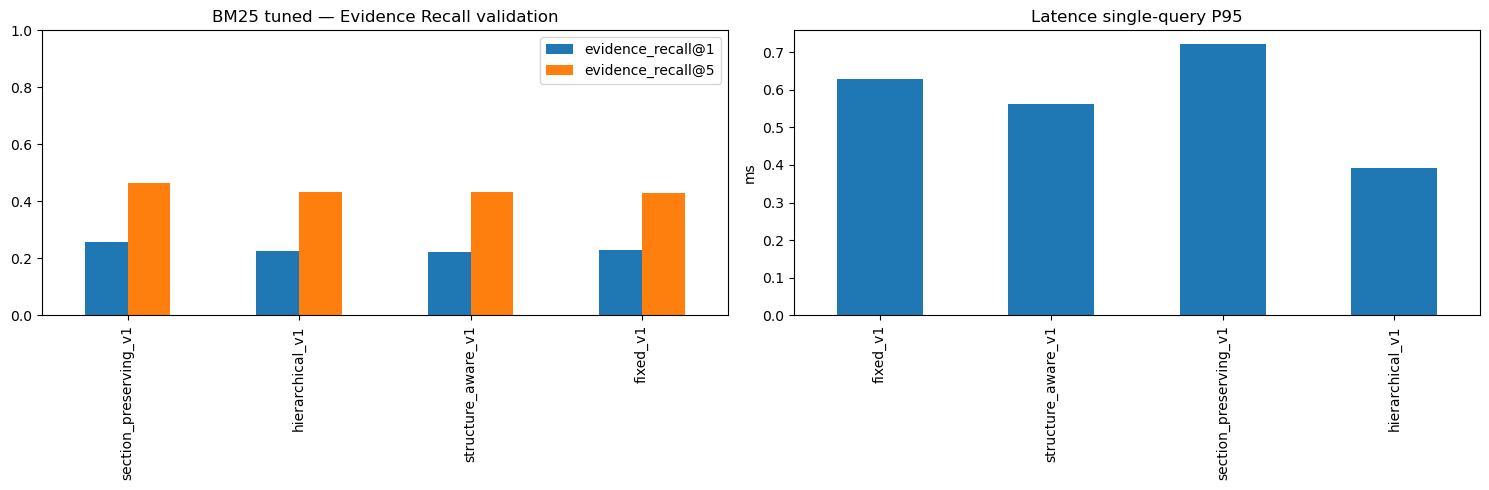

In [10]:
validation_default = summary_df[
    (summary_df["run"] == "default")
    & (summary_df["split"] == "validation")
    & (summary_df["slice"] == "official_primary")
][
    ["strategy", "k1", "b", "queries", "evidence_recall@1", "evidence_recall@5",
     "all_evidence_hit@5", f"mrr@{MAX_K}", "chunk_ndcg@10", "zero_result_rate"]
].sort_values("evidence_recall@5", ascending=False)
validation_tuned = summary_df[
    (summary_df["run"] == "tuned_validation")
    & (summary_df["split"] == "validation")
    & (summary_df["slice"] == "official_primary")
][
    ["strategy", "k1", "b", "queries", "evidence_recall@1", "evidence_recall@5",
     "all_evidence_hit@5", f"mrr@{MAX_K}", "chunk_ndcg@10", "zero_result_rate"]
].sort_values("evidence_recall@5", ascending=False)

print("--- Baseline par défaut — validation / cohorte principale ---")
display(validation_default.round(4))
print("--- Après tuning — validation / cohorte principale ---")
display(validation_tuned.round(4))
print("--- Paramètres sélectionnés ---")
display(pd.DataFrame([{"strategy": key, **value} for key, value in selected_parameters.items()]))
print("--- Performance ---")
display(performance_df.round(3))

tuned_domain_validation = domain_summary_df[
    (domain_summary_df["run"] == "tuned_validation") & (domain_summary_df["split"] == "validation")
]
display(tuned_domain_validation.round(4))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
validation_tuned.set_index("strategy")[["evidence_recall@1", "evidence_recall@5"]].plot.bar(ax=axes[0])
performance_df.set_index("strategy")["single_query_latency_p95_ms"].plot.bar(ax=axes[1])
axes[0].set_title("BM25 tuned — Evidence Recall validation")
axes[0].set_ylim(0, 1)
axes[0].set_xlabel("")
axes[1].set_title("Latence single-query P95")
axes[1].set_ylabel("ms")
axes[1].set_xlabel("")
plt.tight_layout()
plt.show()

## 10. Persistance du rapport et du manifeste

In [11]:
generated_at = datetime.now(timezone.utc).isoformat()
summary_path = OUTPUT_ROOT / "metrics_summary.json"
domain_path = OUTPUT_ROOT / "metrics_by_domain.json"
grid_path = OUTPUT_ROOT / "tuning_grid.json"
performance_path = OUTPUT_ROOT / "performance.json"
write_json_atomic(summary_path, dataframe_records(summary_df))
write_json_atomic(domain_path, dataframe_records(domain_summary_df))
write_json_atomic(grid_path, dataframe_records(grid_df))
write_json_atomic(performance_path, dataframe_records(performance_df))

top_level_outputs = {
    "metrics_summary.json": artifact_metadata(summary_path, len(summary_df)),
    "metrics_by_domain.json": artifact_metadata(domain_path, len(domain_summary_df)),
    "tuning_grid.json": artifact_metadata(grid_path, len(grid_df)),
    "performance.json": artifact_metadata(performance_path, len(performance_df)),
}
quality = {
    "status": quality_status,
    "errors": quality_errors,
    "warnings": quality_warnings,
    "loaded_splits": sorted(loaded_splits),
    "locked_splits_not_loaded": sorted(locked_splits),
    "test_evaluated": False,
}
manifest = {
    "schema_version": "1.0.0",
    "pipeline_stage": "04_bm25_retrieval_evaluation",
    "generated_at_utc": generated_at,
    "experiment_id": experiment_id,
    "experiment_fingerprint": experiment_fingerprint,
    "implementation_version": config["implementation_version"],
    "configuration_path": str(CONFIG_PATH.relative_to(PROJECT_ROOT)),
    "configuration_hash": config_hash,
    "benchmark": {
        "benchmark_id": config["benchmark_id"],
        "manifest_path": str(benchmark_manifest_path.relative_to(PROJECT_ROOT)),
        "manifest_sha256": file_sha256(benchmark_manifest_path),
        "development_splits": benchmark_split_inputs,
        "locked_splits": sorted(locked_splits),
    },
    "chunk_inputs": chunking_inputs,
    "analyzer": analyzer_config,
    "default_parameters": default_parameters,
    "selected_parameters_by_strategy": selected_parameters,
    "index_statistics": index_statistics,
    "artifacts_by_strategy": persisted_artifacts,
    "outputs": top_level_outputs,
    "quality": quality,
    "decision": "bm25_baseline_complete_chunking_not_final",
}
manifest_path = OUTPUT_ROOT / "manifest.json"
write_json_atomic(manifest_path, manifest)

report = {
    **manifest,
    "validation_default_official_primary": dataframe_records(validation_default),
    "validation_tuned_official_primary": dataframe_records(validation_tuned),
    "metrics_summary": dataframe_records(summary_df),
    "metrics_by_domain": dataframe_records(domain_summary_df),
    "tuning_grid": dataframe_records(grid_df),
    "performance": dataframe_records(performance_df),
}
report_path = REPORT_ROOT / "bm25_report.json"
write_json_atomic(report_path, report)
print(f"Artefacts : {OUTPUT_ROOT}")
print(f"Rapport   : {report_path}")

Artefacts : C:\Users\dhiar\OneDrive\Bureau\Project\RAG Assistant\data\processed\multidoc2dial_v1\bm25_experiments\bm25_retrieval_baseline_v1_8def866155
Rapport   : C:\Users\dhiar\OneDrive\Bureau\Project\RAG Assistant\reports\generated\multidoc2dial_v1\bm25_experiments\bm25_retrieval_baseline_v1_8def866155\bm25_report.json


## 11. Relecture indépendante des artefacts

In [12]:
persisted_manifest = load_json(manifest_path)
assert persisted_manifest["experiment_id"] == experiment_id
assert persisted_manifest["experiment_fingerprint"] == experiment_fingerprint
assert persisted_manifest["quality"]["status"] == "passed"
assert persisted_manifest["quality"]["test_evaluated"] is False
assert persisted_manifest["decision"] == "bm25_baseline_complete_chunking_not_final"

for filename, metadata in persisted_manifest["outputs"].items():
    path = OUTPUT_ROOT / filename
    assert file_sha256(path) == metadata["sha256"]

for strategy_name, artifacts in persisted_manifest["artifacts_by_strategy"].items():
    index_dir = OUTPUT_ROOT / "indexes" / strategy_name
    matrix_path = index_dir / "tf_matrix.npz"
    metadata_path = index_dir / "index_metadata.json"
    assert file_sha256(matrix_path) == artifacts["index"]["tf_matrix.npz"]["sha256"]
    assert file_sha256(metadata_path) == artifacts["index"]["index_metadata.json"]["sha256"]
    loaded_matrix = sparse.load_npz(matrix_path)
    loaded_metadata = load_json(metadata_path)
    assert loaded_matrix.shape == (len(loaded_metadata["chunk_ids"]), len(loaded_metadata["vocabulary"]))

    for run_name in ("default_validation", "tuned_validation"):
        ranking_path = OUTPUT_ROOT / "rankings" / strategy_name / f"{run_name}.jsonl"
        ranking_metadata = artifacts[f"{run_name}_rankings"]
        assert file_sha256(ranking_path) == ranking_metadata["sha256"]
        count = sum(1 for _ in iter_jsonl(ranking_path))
        assert count == ranking_metadata["records"] == len(validation_examples)

print("✅ Index, rankings, métriques et hashes relus avec succès. Le test est toujours verrouillé.")

✅ Index, rankings, métriques et hashes relus avec succès. Le test est toujours verrouillé.


## 12. Interprétation attendue

Les résultats BM25 constituent une baseline lexicale et une première ablation du chunking. Ils ne suffisent pas encore pour choisir définitivement la stratégie de production : les mêmes quatre candidats devront ensuite être comparés avec le dense retrieval OpenAI, puis avec l’hybride BM25 + dense.